# SciPy: `scipy.special`

*when SciPy offers a dedicated function like `expm1` or `logsumexp` instead of the obvious formula, what does that buy a user in accuracy, and what does it cost?* compared against a high-precision `mpmath` reference.

## 2. Example run: `expm1` vs `exp(x) - 1`

For small $x$, $e^x - 1$ is a subtraction of two nearly equal numbers, so the *algorithm* `np.exp(x) - 1` loses digits to cancellation. The *problem* is fine. The relative condition number of $f(x)=e^x-1$ is
$$\kappa(x) = \left|\frac{x f'(x)}{f(x)}\right| = \frac{|x| e^x}{|e^x-1|} \to 1 \text{ as } x\to 0,$$
so it is well conditioned near 0. Any digits lost are the algorithm's fault, which is exactly what `scipy.special.expm1` is meant to avoid.

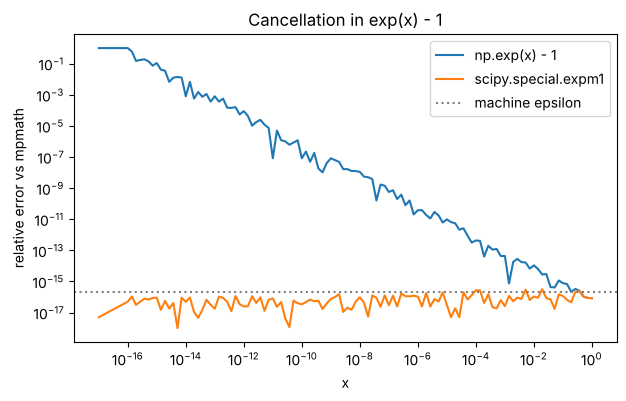

In [1]:
import numpy as np, mpmath as mp, time
import matplotlib.pyplot as plt
from scipy import special
mp.mp.dps = 60

def rel_err(approx, exact):
    return abs((mp.mpf(float(approx)) - exact) / exact)

xs = np.logspace(-17, 0, 120)
naive, stable = [], []
for x in xs:
    ex = mp.expm1(mp.mpf(float(x)))
    naive.append(float(rel_err(np.exp(x) - 1, ex)))
    stable.append(float(rel_err(special.expm1(x), ex)))
naive, stable = np.array(naive), np.array(stable)

fig, ax = plt.subplots(figsize=(7,4))
ax.loglog(xs, np.maximum(naive,1e-18), label='np.exp(x) - 1')
ax.loglog(xs, np.maximum(stable,1e-18), label='scipy.special.expm1')
ax.axhline(2.2e-16, ls=':', c='gray', label='machine epsilon')
ax.set_xlabel('x'); ax.set_ylabel('relative error vs mpmath')
ax.set_title('Cancellation in exp(x) - 1'); ax.legend(); plt.show()

## 3. Same idea at larger scale: `logsumexp`

Computing $\log\sum_i e^{x_i}$ naively overflows for large $x_i$ and underflows for very negative ones. This is a real concern for anyone working with log-probabilities.

In [2]:
from scipy.special import logsumexp
rows = []
for shift in [0, 100, 500, 800, 1000, -800, -1000]:
    x = np.array([1.0, 2.0, 3.0]) + shift
    with np.errstate(all='ignore'):
        naive_v = np.log(np.sum(np.exp(x)))
    ref = mp.log(sum(mp.e**mp.mpf(float(v)) for v in x))
    rows.append((shift, naive_v, logsumexp(x), float(ref)))
print(f"{'shift':>6} {'naive':>14} {'logsumexp':>14} {'mpmath ref':>14}")
for s,n,l,r in rows:
    print(f"{s:>6} {n:>14.6g} {l:>14.6g} {r:>14.6g}")

 shift          naive      logsumexp     mpmath ref
     0        3.40761        3.40761        3.40761
   100        103.408        103.408        103.408
   500        503.408        503.408        503.408
   800            inf        803.408        803.408
  1000            inf        1003.41        1003.41
  -800           -inf       -796.592       -796.592
 -1000           -inf       -996.592       -996.592


The naive version returns `inf` (overflow) for large positive shifts and `-inf` (underflow) for large negative ones. `logsumexp` matches the reference in all cases. This is an *algorithm* choice: factor out the max before exponentiating.

## 4. Cost: is the accurate version more expensive?

For a stakeholder who cares about speed, the question is whether the stable function costs more. I measure time per element on a size-$N$ array, and also time the `mpmath` reference to show what "just use more digits" costs.

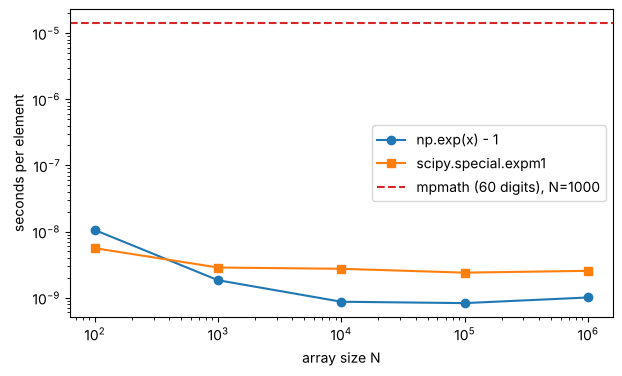

expm1 / naive time ratio at N=1e6: 2.53
mpmath / expm1 at N=1e3: 4950x slower


In [3]:
def bench(f, x, reps=5):
    best = 1e9
    for _ in range(reps):
        t = time.perf_counter(); f(x); best = min(best, time.perf_counter()-t)
    return best / len(x)

Ns = [10**k for k in range(2, 7)]
t_naive, t_stable = [], []
for N in Ns:
    x = np.random.uniform(1e-10, 1e-2, N)
    t_naive.append(bench(lambda v: np.exp(v)-1, x))
    t_stable.append(bench(special.expm1, x))
x = np.random.uniform(1e-10, 1e-2, 1000)
t_mp = bench(lambda v: [mp.expm1(mp.mpf(float(a))) for a in v], x, reps=2)

fig, ax = plt.subplots(figsize=(7,4))
ax.loglog(Ns, t_naive, 'o-', label='np.exp(x) - 1')
ax.loglog(Ns, t_stable, 's-', label='scipy.special.expm1')
ax.axhline(t_mp, c='C3', ls='--', label='mpmath (60 digits), N=1000')
ax.set_xlabel('array size N'); ax.set_ylabel('seconds per element'); ax.legend(); plt.show()
print(f"expm1 / naive time ratio at N=1e6: {t_stable[-1]/t_naive[-1]:.2f}")
print(f"mpmath / expm1 at N=1e3: {t_mp/t_stable[1]:.0f}x slower")

**Takeaway:** in my run `expm1` was about 2.6x slower per element than the naive `np.exp(x) - 1` at N=1e6 (it does more work to avoid cancellation, and the naive version is two very simple vectorized operations), but still thousands of times faster than 60-digit `mpmath` (~4,700x at N=1e3). So accuracy isn't free here, but it's cheap compared to the brute-force alternative. On an accuracy-vs-cost plot, the naive formula is fastest but wrong near 0, `mpmath` is accurate but very slow, and `expm1` sits in between. Timings will vary by machine, so rerun before presenting.

## 5. Different stakeholders, different axes

| Stakeholder | Cares about | Axis |
|---|---|---|
| Scientist running one calculation | Is my answer right? | digits correct vs input range |
| ML/stats library author | Throughput on big arrays | seconds per element |
| SciPy maintainer | Can we test and maintain it? | error vs reference across the whole domain, plus lines of code/tests |

## 6. Question I have for the project

How do `scipy.special` maintainers decide a function is "accurate enough," and is that threshold written down (e.g. a target ulp error per function), or is it case by case in the tests?

## 7. Proposed group-project experiment

**Measure:** maximum relative error (in ulps) of a selection of `scipy.special` functions (`expm1`, `log1p`, `erfc`, `gammaln`, `logsumexp`) against `mpmath` over their full input range, plus runtime per element.
**Present as:** one figure per function with relative error on the y-axis (log) and input $x$ on the x-axis, and a summary scatter of *max error vs time per element*, one point per function. The goal is to find input regions where accuracy drops and see whether they match the conditioning of the underlying problem.